# MNIST Handwritten Digit Classification

In [1]:
# importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('./mnist_train.csv/mnist_train.csv')
df.sample()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
11356,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
x = df.iloc[:,1:].to_numpy()
y = df['label']

In [4]:
x.shape

(60000, 784)

In [5]:
y.shape

(60000,)

In [6]:
y.unique()

array([5, 0, 4, 1, 9, 2, 3, 6, 7, 8])

In [7]:
# normalize
x = x/255
# one hot encoding 
y_encoded = np.eye(10)[y]

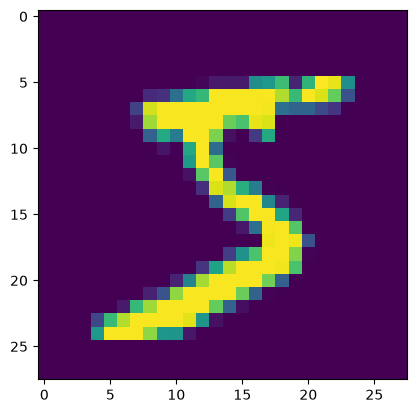

In [8]:
# data samples using head map
plt.imshow(x[0].reshape(28,28))
plt.show()

## Neural Network

### Layer Class

In [9]:
class Layer:

    def __init__(self, n_inputs, n_neurons):
        self.weights = 0.01 * np.random.randn(n_inputs, n_neurons)
        self.biases = np.zeros((1, n_neurons))

    def forward(self, inputs):
        self.inputs = inputs
        self.outputs = np.dot(self.inputs, self.weights) + self.biases

    def backward(self, dvalues):
        # weights
        self.dweights = np.dot(self.inputs.T, dvalues)
        # inputs
        self.dinputs = np.dot(dvalues, self.weights.T)
        # biases
        self.dbiases = np.sum(dvalues, axis=0, keepdims=True)

### ReLU Activation

In [10]:
class ReLUActivation:
    def forward(self, inputs):
        self.inputs = inputs
        self.outputs = np.maximum(self.inputs, 0)

    def backward(self, dvalues):
        self.dinputs = dvalues.copy()
        self.dinputs[self.inputs<=0] = 0

### Softmax Activation

In [11]:
class SoftmaxActivation:
    def forward(self, inputs):
        exp_values = np.exp(inputs-np.max(inputs, axis=1, keepdims=True))
        self.outputs = exp_values / np.sum(exp_values, axis=1, keepdims=True)

### CCEL

In [12]:
class Loss:
    def calculate_loss(self, y_true, y_pred):
        return np.mean(self.forward(y_true, y_pred))

class CategoricalCrossEntropyLoss(Loss):

    def forward(self, y_true, y_pred):
        # y_true -> one hot encoded
        y_pred_clip = np.clip(y_pred, 1e-7, 1-1e-7)
        # prevent 0 and 1
        correct_confidences = np.sum(y_pred_clip * y_true, axis=1)
        neg_log_liklihoods = - np.log(correct_confidences)

        return neg_log_liklihoods

    def backward(self, dvalues, y_true):
        # y_true -> one hot encoded
        self.dinputs = - y_true/dvalues
        self.dinputs = self.dinputs/len(dvalues)

### Combination of Softmax & CCEL

In [13]:
class SoftMax_CCEL:
    def __init__(self):
        self.activation = SoftmaxActivation()
        self.ccel = CategoricalCrossEntropyLoss()

    def forward(self, inputs, y_true):
        self.activation.forward(inputs)
        self.outputs = self.activation.outputs

        return self.ccel.calculate_loss(y_true, self.outputs)

    def backward(self, dvalues, y_true):
        self.dinputs = dvalues - y_true
        # prediction - true value
        self.dinputs /= len(dvalues)

### Adam Opt

In [14]:
class AdamOptimizer:
    
    def __init__(self, learning_rate=0.001, decay=0., epsilon=1e-7, beta_1=0.9, beta_2=0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta_1
        self.beta_2 = beta_2

    def pre_update_params(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate * (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):
        # If layer does not contain cache arrays, create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * layer.weight_momentums + (1 - self.beta_1) * layer.dweights
        layer.bias_momentums = self.beta_1 * layer.bias_momentums + (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iteration is 0 at first pass and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / (1 - self.beta_1 ** (self.iterations + 1))
        bias_momentums_corrected = layer.bias_momentums / (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + (1 - self.beta_2) * layer.dweights**2
        layer.bias_cache = self.beta_2 * layer.bias_cache + (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / (1 - self.beta_2 ** (self.iterations + 1))
        bias_cache_corrected = layer.bias_cache / (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization with square rooted cache
        layer.weights += -self.current_learning_rate * weight_momentums_corrected / (np.sqrt(weight_cache_corrected) + self.epsilon)
        layer.biases += -self.current_learning_rate * bias_momentums_corrected / (np.sqrt(bias_cache_corrected) + self.epsilon)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1

## Model Training

### 3 Layer Network

In [15]:
# first layer 
l1 = Layer(784, 128)
af1 = ReLUActivation()

# second layer 
l2 = Layer(128, 64)
af2 = ReLUActivation()

# third layer 
l3 = Layer(64, 10)
loss_af = SoftMax_CCEL()

# Adam Optimizer
opt = AdamOptimizer(learning_rate=0.01, decay=1e-5)

epochs = 101

In [16]:
for _ in range(epochs):
    # layer one
    l1.forward(x)
    af1.forward(l1.outputs)

    # layer two 
    l2.forward(af1.outputs)
    af2.forward(l2.outputs)

    # layer three 
    l3.forward(af2.outputs)
    loss = loss_af.forward(l3.outputs, y_encoded)

    # predictions
    predictions = np.argmax(loss_af.outputs, axis=1)

    # accuracy
    acc = np.mean(predictions == y)

    # backward pass
    loss_af.backward(loss_af.outputs, y_encoded)
    l3.backward(loss_af.dinputs)
    af2.backward(l3.dinputs)
    l2.backward(af2.dinputs)
    af1.backward(l2.dinputs)
    l1.backward(af1.dinputs)

    # optimizers 
    opt.pre_update_params()
    opt.update_params(l1)
    opt.update_params(l2)
    opt.update_params(l3)
    opt.post_update_params()

    if _%10 == 0:
        print('Accuracy', acc, '\nLoss : ', loss, '\nIteration : ', _)

Accuracy 0.15153333333333333 
Loss :  2.302542500108957 
Iteration :  0
Accuracy 0.7561833333333333 
Loss :  0.7591980748616808 
Iteration :  10
Accuracy 0.84775 
Loss :  0.4954467807992689 
Iteration :  20
Accuracy 0.8913 
Loss :  0.37046763077431016 
Iteration :  30
Accuracy 0.9142166666666667 
Loss :  0.2937007068111114 
Iteration :  40
Accuracy 0.9290666666666667 
Loss :  0.242967348791955 
Iteration :  50
Accuracy 0.9427 
Loss :  0.19998373612612333 
Iteration :  60
Accuracy 0.95255 
Loss :  0.16645654874337948 
Iteration :  70
Accuracy 0.9588833333333333 
Loss :  0.14305928481665808 
Iteration :  80
Accuracy 0.9637666666666667 
Loss :  0.12501893306237702 
Iteration :  90
Accuracy 0.9674666666666667 
Loss :  0.11224412621551837 
Iteration :  100


## 2 Layer Network

In [17]:
# first layer 
l1 = Layer(784, 128)
af1 = ReLUActivation()

# second layer 
l2 = Layer(128, 10)
loss_af = SoftMax_CCEL()

# Adam Optimizer
opt = AdamOptimizer(learning_rate=0.01, decay=1e-5)

epochs = 101

In [18]:
for _ in range(epochs):
    # layer one
    l1.forward(x)
    af1.forward(l1.outputs)

    # layer two 
    l2.forward(af1.outputs)
    loss = loss_af.forward(l2.outputs, y_encoded)

    # predictions
    predictions = np.argmax(loss_af.outputs, axis=1)

    # accuracy
    acc = np.mean(predictions == y)

    # backward pass
    loss_af.backward(loss_af.outputs, y_encoded)
    l2.backward(loss_af.dinputs)
    af1.backward(l2.dinputs)
    l1.backward(af1.dinputs)

    # optimizers 
    opt.pre_update_params()
    opt.update_params(l1)
    opt.update_params(l2)
    opt.post_update_params()

    if _%10 == 0:
        print('Accuracy', acc, '\nLoss : ', loss, '\nIteration : ', _)

Accuracy 0.15543333333333334 
Loss :  2.302184681853714 
Iteration :  0
Accuracy 0.8706333333333334 
Loss :  0.44947191880351434 
Iteration :  10
Accuracy 0.9128333333333334 
Loss :  0.334926737937736 
Iteration :  20
Accuracy 0.9295833333333333 
Loss :  0.25385788804589954 
Iteration :  30
Accuracy 0.94485 
Loss :  0.19777262776937465 
Iteration :  40
Accuracy 0.95555 
Loss :  0.159237766529953 
Iteration :  50
Accuracy 0.9630833333333333 
Loss :  0.13027618464333918 
Iteration :  60
Accuracy 0.9695833333333334 
Loss :  0.10828995603345494 
Iteration :  70
Accuracy 0.9745166666666667 
Loss :  0.09109025044226107 
Iteration :  80
Accuracy 0.9781 
Loss :  0.07753050640316934 
Iteration :  90
Accuracy 0.9816333333333334 
Loss :  0.06638003576875832 
Iteration :  100


### Test Data

In [19]:
df_test = pd.read_csv('./mnist_test.csv/mnist_test.csv')
x_test, y_test = df_test.iloc[:,1:].to_numpy(), df_test['label']
y_test_encoded = np.eye(10)[y_test]
x_test = x_test/255

In [20]:
print(x_test.shape, y_test.shape, y_test_encoded.shape)

(10000, 784) (10000,) (10000, 10)


In [21]:
# first layer 
l1.forward(x_test)
af1.forward(l1.outputs)

# second layer 
l2.forward(af1.outputs)
loss_test = loss_af.forward(l2.outputs, y_test_encoded)

# prediction 
predictions_test = np.argmax(loss_af.outputs, axis=1)

# accuracy
acc_test = np.mean(predictions_test == y_test)

print('Accuracy : ', acc_test, 'Loss : ', loss_test)

Accuracy :  0.9679 Loss :  0.10577340495484222


## Conclusion

I trained a fully connected neural network from scratch using NumPy for MNIST handwritten digit classification. The model was implemented without deep-learning frameworks, including manual forward propagation, backpropagation, Softmax, categorical cross-entropy loss, and the Adam optimizer.

### 2 Layer Network
Results after 100 epochs:

* Training Accuracy: approximately 98%
* Training Loss: approximately 0.06
* Test Accuracy: approximately 97%
* Test Loss: approximately 0.10

The small difference between training and test accuracy indicates that the model generalized reasonably well and showed no significant overfitting.

### 3 Layer Network
Results:
* Training Accuracy: 96%
* Training Loss: 0.11

The deeper model performed slightly worse on both the training and test datasets.

Adding an extra hidden layer did not improve performance in this experiment. This shows that increasing network depth does not automatically improve accuracy. The deeper network introduced a more complex optimization problem and did not provide enough additional benefit for the MNIST dataset.
The simpler architecture,performed better and achieved approximately 97% test accuracy.

The experiment demonstrates the importance of comparing neural-network architectures empirically and changing one hyperparameter at a time. A model should be evaluated not only by training accuracy but also by its ability to generalize to unseen data.